---
title: "Sáez and Carbonell (1985): trickle-flow holdup and pressure drop from relative permeabilities"
description: "Do the paper's printed results follow from its printed relations? The derivation chain, the coupled solve, the surfactant ratios of Table 5, the printed statistics and the markers of Figure 8, each checked with numbers."
categories: [sec:G, struct:S3, tier:T1, data:tier4]
date: 2026-11-28
---

# Sáez and Carbonell (1985): holdup and pressure drop from relative permeabilities

**Catalog ID:** `G1.3` · **Structures:** `S3` · **Tier:** T1

Sáez and Carbonell wrote the volume-averaged momentum balances of gas and liquid
in a packed bed with Ergun drag per phase divided by a relative permeability, and
fitted two one-exponent laws, $k_L = \delta^{2.43}$ for the liquid and
$k_G = S_G^{4.8}$ for the gas. One pair of laws then gives liquid holdup and
pressure drop together. This page asks whether the paper's printed results follow
from its printed relations: the derivation chain, the coupled model solved over a
flow sweep, the surfactant ratios of Table 5, the printed statistics, and the
markers of Figure 8 against the band the text says holds them.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.8"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "G1.3-saez-carbonell-relative-permeability"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults are not needed.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.optimize import minimize_scalar

from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from pymrm.checks import check_jacobian, find_roots, residual_check

import model as M

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])

## Background

In cocurrent gas-liquid downflow through a packed bed at low interaction (the
trickling regime) the liquid holdup and the pressure drop are the two quantities a
designer needs first. Most correlations of the time fitted each separately. Sáez and
Carbonell (AIChE J. 31(1), 52-62, 1985, doi 10.1002/aic.690310105) instead start
from the two-fluid momentum balances with the Ergun drag of each phase divided by a
relative permeability that depends on saturation only, as in flow through porous
media. Two exponents, one per phase, are fitted to literature data: 2.43 on 70
stagnant-gas points (Table 3, p. 56) and 4.8 on the points with both pressure drop
and holdup and a column-to-particle diameter ratio above 20 (p. 58). The paper then
states mean deviations of 12.7 % on 59 holdup points and 21.9 % on 49 pressure-drop
points (Table 7, p. 59) and shows the comparisons in Figures 7 and 8.

The paper prints no table of operating conditions, so the model cannot be rerun on
its data points. What can be checked is every place where a printed number is
decided by printed relations: the derivation from the balances to Eqs. 34, 50 and
51; the surfactant test of Table 5, the only comparison outside the fitted laws
whose inputs are printed; the statistics of Tables 3, 4 and 7 against one another;
and the plotted markers of Figure 8 against the printed band. The model itself is
solved over a flow sweep to show what it predicts and how strongly the pressure drop
depends on the holdup.

## The published model

Subscript $L$ is the paper's $\beta$ (liquid), $G$ its $\gamma$ (gas); $z$ points
down. With $\mathrm{Re}^{\ast} = \rho\langle v\rangle d_e/(\mu(1-\varepsilon))$ and
$\mathrm{Ga}^{\ast} = \rho^2 g d_e^3\varepsilon^3/(\mu^2(1-\varepsilon)^3)$ (nomenclature,
p. 61, with $\mu$ restored in $\mathrm{Re}^{\ast}$, see A1 below), the Ergun drag over
$\rho g$ is

$$X_a = A\,\frac{\mathrm{Re}^{\ast}_a}{\mathrm{Ga}^{\ast}_a} + B\,\frac{\mathrm{Re}^{\ast 2}_a}{\mathrm{Ga}^{\ast}_a},\qquad A = 180,\; B = 1.8 .$$

| Eq. (page) | relation | code |
|---|---|---|
| 8 (p. 54) | $\varepsilon^0 = 1/(20 + 0.9\,\mathrm{Eo}^{\ast})$, $\mathrm{Eo}^{\ast} = \rho_L g d_e^2\varepsilon^2/(\sigma(1-\varepsilon)^2)$ | `static_holdup`, `eotvos` |
| 13, 14 (p. 55) | $-dP_a/dz + \rho_a g = (X_a/k_a)\rho_a g$ | `momentum_residuals` |
| 20 (p. 56) | the capillary pressure in Leverett's J-function form; the assumption stated after it is that $dP_c/dz$ is negligible in Eq. 19, so $dP_L/dz = dP_G/dz$ | |
| 21 (p. 56) | $X_L/k_L - (\rho_G/\rho_L)X_G/k_G = 1 - \rho_G/\rho_L$ | `params(exact=True)` |
| 24 (p. 56) | $\delta = (\varepsilon_L - \varepsilon^0)/(\varepsilon - \varepsilon^0)$ | `holdup` |
| 32 (p. 56) | $k_L = \delta^{2.43}$ | `a` |
| 34 (p. 57) | stagnant gas: $\delta = X_L^{0.41}$ | `stagnant_delta` |
| 35 to 37 (p. 58) | surfactant ratio $\varepsilon^D_{L,i}/\varepsilon^D_{L,o}$ | `ratio_printed`, `ratio_rederived` |
| 48 (p. 58) | $k_G = S_G^{4.80}$, $S_G = 1 - \varepsilon_L/\varepsilon$ (Eq. 52) | `c`, `gas_saturation` |
| 50 (p. 59) | $\psi_G = X_G/S_G^{4.8}$, $-dP/dz = \rho_G g(\psi_G - 1)$ (Eqs. 38 to 41) | `state` |
| 51 (p. 59) | $X_L/\delta^{2.43} - (\rho_G/\rho_L)X_G/S_G^{4.8} = 1$ | `pair_residual` |

Readings and misprints, each re-derived on this page:

- **A1.** The nomenclature prints $\mathrm{Re}^{\ast} = \rho\langle v\rangle d_e/(1-\varepsilon)$
  without $\mu$; only with $\mu$ does $X_a$ equal the dimensional Ergun gradient over
  $\rho g$ (checked below).
- **A3.** Eqs. 8, 24 and 34 at equal $\delta$ give
  $\varepsilon^D_i/\varepsilon^D_o = (\varepsilon - \varepsilon^0_i)/(\varepsilon - \varepsilon^0_o)
  = (\zeta_A/\zeta_B)(\zeta_B \mathrm{Eo}^{\ast}_o\varepsilon - 1)/(\zeta_A \mathrm{Eo}^{\ast}_o\varepsilon - 1)$
  with $\zeta_A = 0.9 + 20/\mathrm{Eo}^{\ast}_o$, $\zeta_B = 0.9\,\sigma_o/\sigma_i + 20/\mathrm{Eo}^{\ast}_o$.
  The printed Eq. 35 is $(\zeta_A/\zeta_B)(\zeta_B\varepsilon - 1)/(\zeta_A\varepsilon - 1)$:
  the factor $\mathrm{Eo}^{\ast}_o$ is missing from both brackets.
- **A7.** Eq. 34's exponent 0.41 stands for $1/2.43$.
- **A9.** Eq. 51 is Eq. 21 with the gas weight dropped ("In the equation above, we
  have considered $\rho_\beta \gg \rho_\gamma$", p. 59).
- **A13.** Eq. 13 prints the liquid inertial term as $B\,\mathrm{Re}^{\ast\,\ast}/(k_{Li}\mathrm{Ga}^{\ast})$;
  Eqs. 11, 14 and 19 carry $\mathrm{Re}^{\ast 2}$, read here.
- Eq. 35 drops $\mathrm{Eo}^{\ast}_o$; the nomenclature refers $\psi$ to Eq. 10 where Eq. 40
  defines it; p. 59 says the column-to-particle ratio "was always greater than 10"
  while Table 6 prints 9 for Charpentier et al.; Table 6 gives the filled circle to
  Specchia and Baldi cylinders ($d_c/d_p$ 15) while the fit set of $k_G$ is the
  $d_c/d_p > 20$ data. The page reports these and decides none of them.

## Parameters and assumptions

The page evaluates the model at one test condition T inside every Summary range
(p. 60): air-water at 20 °C on 3 mm spheres, porosity 0.38, liquid flux 5 and gas
flux 0.1 kg/(m² s), with the printed $A = 180$, $B = 1.8$. The printed constants
are read from the data file as strings; the model takes them from one dictionary
`M.PRINTED`, so a break row changes one entry.

Assumptions: equal phase pressure gradients (the assumption stated after Eq. 20, p. 56: $dP_c/dz$ negligible in Eq. 19; untested here);
zero irreducible gas saturation ($\delta_G = S_G$, p. 58); water surface tension
72.8 mN/m for Table 5 (the paper does not print it; 72.0 is shown as an
alternative); the densest sphere packing, $1 - \pi/(3\sqrt 2)$, as the smallest
porosity a packed bed can have.

In [3]:
T = dict(d_e=3.0e-3,      # m, equivalent diameter (spheres: d_p)
         eps=0.38,        # -, bed porosity
         L=5.0,           # kg/(m2 s), liquid mass flux
         G=0.1,           # kg/(m2 s), gas mass flux
         rho_L=998.0,     # kg/m3, water at 20 C
         mu_L=1.0e-3,     # Pa s
         sigma=0.0728,    # N/m
         rho_G=1.2,       # kg/m3, air
         mu_G=1.8e-5,     # Pa s
         g=9.81)          # m/s2
SIGMA_WATER = 72.8            # mN/m, Table 5 reference liquid (not printed; 72.0 as alternative)
SIGMA_WATER_ALT = 72.0
EPS_DENSE = 1 - np.pi / (3 * np.sqrt(2))   # densest sphere packing, the porosity floor
P0 = M.params()

PN = load_data("saez-carbonell-1985-printed-numbers.csv", page=PAGE, dtype=str).set_index("name")
PRN = PN["printed"]
num = lambda s: float(str(s).replace(",", ""))  # noqa: E731

# the model's constants against the printed strings
for key, name in [("A", "eq33_A"), ("B", "eq33_B"), ("a", "eq32_a"), ("c", "eq46_c"),
                  ("e34", "eq34_exp"), ("eo_a", "eq8_const"), ("eo_b", "eq8_coef")]:
    assert P0[key] == num(PRN[name]), (key, name)
assert num(PRN["eq48_c"]) == num(PRN["eq46_c"]), "Eq. 46 and Eq. 48 print the same exponent"
assert num(PRN["p58_A"]) == P0["A"] and num(PRN["p58_B"]) == P0["B"]

g_T = M.groups(T, P0)
RANGES = [("Re_G", "sum_re_g_min", "sum_re_g_max"), ("Re_L", "sum_re_l_min", "sum_re_l_max"),
          ("Ga_G", "sum_ga_g_min", "sum_ga_g_max"), ("Ga_L", "sum_ga_l_min", "sum_ga_l_max"),
          ("Eo", "eq8_eo_min", "eq8_eo_max")]
for k, lo, hi in RANGES:
    assert num(PRN[lo]) <= g_T[k] <= num(PRN[hi]), f"T outside the Summary range of {k}"
print(pd.DataFrame({k: [g_T[k], PRN[lo], PRN[hi]] for k, lo, hi in RANGES},
                   index=["at T", "Summary min", "Summary max"]).T.to_string())

              at T Summary min Summary max
Re_G      26.88172           5       6,000
Re_L     24.193548           5       1,500
Ga_G    271.035373         150         5e5
Ga_L  60739.271043         4e4       1.3e8
Eo        0.454668        0.25          30


## The data

- `saez-carbonell-1985-printed-numbers.csv`: every constant, table entry and stated
  statistic the page uses, as printed, with journal and PDF page (journal page = PDF
  page + 51). Read as strings.
- `saez-carbonell-1985-fig8.csv`: Figure 8 (p. 60), digitised from the native 300 ppi
  scan by `data/digitise.py` (committed; it takes the PDF path and stores no image).
  Of the points the paper states, a few markers can be read one by one; the rest sit
  in blobs of touching markers, kept as cluster rows with the range of their
  pixels. Hidden markers are not invented. Figure 7 (pressure drop) is not digitised
  on this page, and neither is Figure 5.
- `check_values.csv`: 66 values computed from the paper's equations by an
  independent script (not the page), asserted before the first claim.

No dataset is borrowed from another page.

In [4]:
FIG8 = load_data("saez-carbonell-1985-fig8.csv", page=PAGE)
for f in ("saez-carbonell-1985-printed-numbers.csv", "saez-carbonell-1985-fig8.csv"):
    print(cite_data(load_meta(f, page=PAGE)))
MK = FIG8[FIG8.kind == "marker"].reset_index(drop=True)
CL = FIG8[FIG8.kind == "cluster"].reset_index(drop=True)
LN = FIG8[FIG8.kind == "line"].set_index("symbol")["offset_min_dec"]
# pixels per decade, recovered from the CSV's own calibration (exp, cal are affine in log10)
PXX = 1 / np.polyfit(MK.x_px, np.log10(MK.exp), 1)[0]
PXY = -1 / np.polyfit(MK.y_px, np.log10(MK.cal), 1)[0]
READ_PX = 2.0                                   # chosen reading error per coordinate (sidecar)
E_D = np.hypot(READ_PX / PXX, READ_PX / PXY)    # decades in log10(cal/exp)
print(f"{len(MK)} readable markers, {len(CL)} cluster rows; {PXX:.2f} and {PXY:.2f} px per decade;"
      f" reading error {E_D:.5f} decades")

Saez, A. E.; Carbonell, R. G. (1985) — AIChE Journal 31(1), 52-62 — doi:10.1002/aic.690310105 — table
Saez, A. E.; Carbonell, R. G. (1985) — AIChE Journal 31(1), 52-62 — doi:10.1002/aic.690310105 — digitised from Fig. 8, journal p. 60 (PDF page 9)
13 readable markers, 5 cluster rows; 375.61 and 373.63 px per decade; reading error 0.00755 decades


## PyMRM implementation

Nothing is discretised. The coupled model is the algebraic pair of Eq. 51 and Eq. 50
per operating point, unknowns $(\delta, \psi)$:

$$r_1 = X_L\delta^{-2.43} - (\rho_G/\rho_L)\,\psi - 1,\qquad r_2 = \psi\,S_G(\delta)^{4.8} - X_G,$$

with the pole of Eq. 50 multiplied out in $r_2$. `pymrm.newton` solves the pairs of
all sweep points at once with the analytic sparse Jacobian (one 2x2 block per point,
built in CSC), `bounds` keeping $\delta$ in (0, 1) where the residual is defined, the
unknowns scaled ($\delta \sim 1$, $\psi \sim 300$) and a relative step test
(`tol=0`, `rtol=1e-12`, pitfall P7), started from the stagnant-gas closed form. The
second route eliminates $\psi$ and solves the scalar equation
$f(\delta) = X_L\delta^{-2.43} - 1 - (\rho_G/\rho_L)X_G/S_G^{4.8} = 0$ with `brentq`,
point by point: $f$ falls monotonically from $+\infty$ at $\delta \to 0$ to $-\infty$
at $\delta \to 1$, so the bracket holds exactly one root. Crossings and extrema
(the gas flux at which the coupling term reaches 1, the trickle end, the maximum of
the Table 5 ratio, the printed-form roots) are roots found by `pymrm.checks.find_roots`.

In [5]:
LS = np.array([2.0, 5.0, 10.0])                       # kg/(m2 s), the three liquid fluxes
RE_G = np.logspace(np.log10(5.0), np.log10(500.0), 40)
G_SWEEP = RE_G * T["mu_G"] * (1 - T["eps"]) / T["d_e"]
OP_S = dict(T, L=np.repeat(LS, G_SWEEP.size), G=np.tile(G_SWEEP, LS.size))
d_s, psi_s, res_s = M.solve_pair(OP_S, P0)
print(f"newton: {res_s.nit} iterations for {d_s.size} points at once, status {res_s.status},"
      f" backward error {res_s.backward_error:.1e}")
ST_T = M.state(T, P0)
print({k: float(np.squeeze(ST_T[k])) for k in ("delta", "eps_L", "S_G", "psi", "minus_dpdz", "coupling")})

newton: 19 iterations for 120 points at once, status 0, backward error 7.4e-17
{'delta': 0.3264491371442008, 'eps_L': 0.1570529857784402, 'S_G': 0.5867026690041047, 'psi': 292.88419914323146, 'minus_dpdz': 3436.0607923141206, 'coupling': 0.35216536971130036}


### Check values

Every function is asserted against the 66 independent values before any claim is
registered.

In [6]:
def check_values(P):
    """The page's value of every row of check_values.csv, from model.py."""
    sq = lambda v: float(np.squeeze(v))  # noqa: E731
    g = M.groups(T, P)
    c = {"T_Re_L": g["Re_L"], "T_Re_G": g["Re_G"], "T_Ga_L": g["Ga_L"], "T_Ga_G": g["Ga_G"],
         "T_Eo_star": g["Eo"], "T_eps0": g["eps0"], "T_X_L": g["X_L"], "T_X_G": g["X_G"]}
    d34 = M.stagnant_delta(g["X_L"], dict(P, stagnant_exp=P["e34"]))
    dia = M.stagnant_delta(g["X_L"], P)
    c.update(T_delta_stagnant_eq34=d34, T_delta_stagnant_inv_a=dia,
             T_eps_L_stagnant=M.holdup(d34, T["eps"], g["eps0"]))
    st = M.state(T, P)
    for k, n in [("delta", "T_delta"), ("eps_L", "T_eps_L"), ("S_G", "T_S_G"), ("psi", "T_psi_G"),
                 ("gas_mod_grad", "T_gas_modified_gradient_Pa_per_m"),
                 ("minus_dpdz", "T_minus_dPdz_Pa_per_m"), ("coupling", "T_coupling_rhoG_psi_over_rhoL"),
                 ("dlnpsi_dlneps", "T_dlnpsi_dlneps")]:
        c[n] = sq(st[k])
    c["T_holdup_over_stagnant"] = sq(st["eps_L"]) / M.holdup(dia, T["eps"], g["eps0"])
    sx = M.state(T, dict(P, exact=True))
    c.update(T_delta_eq21_exact=sq(sx["delta"]), T_eps_L_eq21_exact=sq(sx["eps_L"]),
             T_psi_G_eq21_exact=sq(sx["psi"]),
             T_eps_L_rel_shift_eq51_vs_eq21=sq(st["eps_L"]) / sq(sx["eps_L"]) - 1)
    c["T_psi_factor_holdup_plus_12p7"] = M.psi_factor(sq(st["eps_L"]), T["eps"], 1.127, P)
    c["T_psi_factor_holdup_minus_12p7"] = M.psi_factor(sq(st["eps_L"]), T["eps"], 0.873, P)
    se = M.state(T, dict(P, A=150.0, B=1.75))
    c.update(T_eps_L_ergun150=sq(se["eps_L"]), T_psi_G_ergun150=sq(se["psi"]))
    c["T_ergun_gas_Pa_per_m"] = M.ergun_gradient(T["rho_G"], T["mu_G"], T["G"], T, P["A"], P["B"])
    c["T_ergun_liquid_Pa_per_m"] = M.ergun_gradient(T["rho_L"], T["mu_L"], T["L"], T, P["A"], P["B"])
    re_fl = M.trickle_end_re(g["Ga_L"], P)
    c.update(T_Re_L_flood_stagnant=re_fl,
             T_L_flood_stagnant_kg_m2s=re_fl * T["mu_L"] * (1 - T["eps"]) / T["d_e"])
    gc = coupling_root(T, P)
    c.update(T_G_coupling_one_kg_m2s=gc, T_Re_G_coupling_one=M.reynolds(gc, T["mu_G"], T, P))
    s0 = 1 - g["eps0"] / T["eps"]
    c.update(T_psi_L0_limit=g["X_G"] * s0**-P["c"], T_psi_L0_over_dry=s0**-P["c"])
    st_ = stats(P, OPT)
    c.update(exp34_inv_a=st_["exp34_inv_a"], exp34_halfunits_from_0p41=st_["exp34_halfunits_from_0p41"])
    for k in ("t7_eps_all_recombined_pct", "t7_eps_gap_over_allowance", "t7_psi_all_recombined_pct",
              "t7_psi_gap_over_allowance", "t4_this_work_recombined_pct", "t4_gap_over_allowance",
              "stag98_recombined_pct", "stag98_gap_over_allowance", "t3_two_param_gain_pct"):
        c[k] = st_[k]
    t5 = table5(P, OPT)
    for k in ("t5_corrected_max_sol1_dense", "t5_corrected_max_sol2_dense", "t5_corrected_max_Eo_sol1_dense",
              "t5_corrected_max_Eo_sol2_dense", "t5_exp_min_over_bound_sol1", "t5_exp_min_over_bound_sol2",
              "t5_corrected_max_sol1_eps036", "t5_corrected_max_sol2_eps036", "t5_eps_needed_for_calc1_upper",
              "t5_printed_eps", "t5_printed_Eo_o", "t5_printed_eps0_water", "t5_printed_eps0_sol1",
              "t5_printed_eps0_sol2", "t5_corrected_at_printed_sol1", "t5_corrected_at_printed_sol2",
              "t5_printed_eps_sigma72", "t5_printed_Eo_o_sigma72"):
        c[k] = t5[k]
    c["t5_eps_dense"] = EPS_DENSE
    return c


def coupling_root(op, P, lo=0.01, hi=5.0):
    """Gas flux at which (rho_G/rho_L) psi = 1 at the liquid flux of ``op``; exactly one root."""
    f = lambda G: float(np.squeeze(M.state(dict(op, G=G), P)["coupling"])) - 1.0  # noqa: E731
    r = find_roots(f, lo, hi, n_scan=40, log=True, xtol=1e-13)
    if len(r["roots"]) != 1:
        raise RuntimeError(f"coupling = 1: {len(r['roots'])} roots ({r['message']})")
    return r["roots"][0]


def printed(o):
    """The printed strings with the overrides of a break row."""
    p = PRN.copy()
    for k, v in o["printed_override"].items():
        p[k] = v
    return p


def stats(P, o):
    """R4: the printed statistics recombined, and the half-unit test of Eq. 34's 0.41."""
    p = printed(o)
    ne, ne2 = int(num(p["t7_n_eps_gt20"])), int(num(p["t7_n_eps_lt20"]))
    npsi, npsi2 = int(num(p["t7_n_psi_gt20"])), int(num(p["t7_n_psi_lt20"]))
    if o["t7_swap"]:
        ne, ne2, npsi, npsi2 = ne2, ne, npsi2, npsi
    out = {}
    out["t7_eps_all_recombined_pct"], out["t7_eps_gap_over_allowance"] = M.recombined(
        [ne, ne2], [p["t7_e_eps_gt20"], p["t7_e_eps_lt20"]], p["t7_e_eps_all"])
    out["t7_psi_all_recombined_pct"], out["t7_psi_gap_over_allowance"] = M.recombined(
        [npsi, npsi2], [p["t7_e_psi_gt20"], p["t7_e_psi_lt20"]], p["t7_e_psi_all"])
    n70 = int(num(p["p57_airwater_n"])) + int(num(p["p57_other_n"]))
    out["t4_this_work_recombined_pct"], out["t4_gap_over_allowance"] = M.recombined(
        [int(num(p["p57_airwater_n"])), int(num(p["p57_other_n"]))],
        [p["p57_airwater_e_pct"], p["p57_other_e_pct"]], p["t4_this_work_pct"])
    out["stag98_recombined_pct"], out["stag98_gap_over_allowance"] = M.recombined(
        [n70, int(num(p["p57_jesser_n"]))], [p["t4_this_work_pct"], p["p57_jesser_e_pct"]],
        p["p57_all_e_pct"])
    out["t3_two_param_gain_pct"] = num(p["t3_ab_e_pct"]) - num(p["t3_free_e_pct"])
    out["exp34_inv_a"] = 1.0 / P["a"]
    out["exp34_halfunits_from_0p41"] = (1.0 / P["a"] - num(p["eq34_exp"])) / M.half_unit(p["eq34_exp"])
    out["_gaps"] = [out[k] for k in ("t7_eps_gap_over_allowance", "t7_psi_gap_over_allowance",
                                     "t4_gap_over_allowance", "stag98_gap_over_allowance")]
    out["_n70_plus_28"] = n70 + int(num(p["p57_jesser_n"]))
    return out


def table5(P, o):
    """R3: the surfactant ratios of Table 5 from Eqs. 8, 24 and 34."""
    p = printed(o)
    s1 = SIGMA_WATER / num(p["p57_sigma_1"])
    s2 = SIGMA_WATER / num(p["p57_sigma_2"])
    exp1 = np.array([num(p[f"t5_exp1_{i}"]) for i in range(1, 5)])
    exp2 = np.array([num(p[f"t5_exp2_{i}"]) for i in range(1, 5)])
    calc1, calc2 = num(p["t5_calc1"]), num(p["t5_calc2"])
    ratio = M.ratio_rederived if o["t5_form"] == "rederived" else M.ratio_printed
    eps_f = o["eps_floor"]
    m1, E1 = M.ratio_max(eps_f, s1, P)
    m2, E2 = M.ratio_max(eps_f, s2, P)

    def bounded_max(s):
        """Second route: bounded maximisation refined from a scan of the whole window."""
        le = np.linspace(-3.0, np.log10(o["search_hi"]), 400)
        v = ratio(eps_f, 10**le, s, P)
        i = int(np.argmax(v))
        lo, hi = le[max(i - 1, 0)], le[min(i + 1, le.size - 1)]
        r = minimize_scalar(lambda x: -ratio(eps_f, 10**x, s, P), bounds=(lo, hi), method="bounded",
                            options=dict(xatol=1e-12))
        return -r.fun

    out = dict(t5_corrected_max_sol1_dense=m1, t5_corrected_max_sol2_dense=m2,
               t5_corrected_max_Eo_sol1_dense=E1, t5_corrected_max_Eo_sol2_dense=E2,
               t5_exp_min_over_bound_sol1=exp1.min() / m1, t5_exp_min_over_bound_sol2=exp2.min() / m2,
               t5_max_root_vs_bounded_search=max(abs(bounded_max(s1) / m1 - 1), abs(bounded_max(s2) / m2 - 1)))
    out["t5_eps_dense"] = eps_f
    out["t5_corrected_max_sol1_eps036"] = M.ratio_max(0.36, s1, P)[0]
    out["t5_corrected_max_sol2_eps036"] = M.ratio_max(0.36, s2, P)[0]
    out["t5_eps_needed_for_calc1_upper"] = M.eps_for_ratio(calc1, P)
    inv = M.printed_inversion(calc1, calc2, s1, s2, P)
    out["t5_printed_n_roots"] = len(inv)
    e_p, E_p = inv[0] if inv else (np.nan, np.nan)
    out.update(t5_printed_eps=e_p, t5_printed_Eo_o=E_p,
               t5_printed_eps0_water=M.static_holdup(E_p, P), t5_printed_eps0_sol1=M.static_holdup(E_p * s1, P),
               t5_printed_eps0_sol2=M.static_holdup(E_p * s2, P),
               t5_corrected_at_printed_sol1=ratio(e_p, E_p, s1, P),
               t5_corrected_at_printed_sol2=ratio(e_p, E_p, s2, P))
    hc = (M.half_unit(p["t5_calc1"]), M.half_unit(p["t5_calc2"])) if o["calc_half"] is None else (o["calc_half"],) * 2
    box = [M.printed_inversion(calc1 + d1 * hc[0], calc2 + d2 * hc[1], s1, s2, P)
           for d1 in (-1, 1) for d2 in (-1, 1)]
    roots = [r[0] for b in box for r in b]
    out["t5_printed_box_one_root"] = sum(len(b) == 1 for b in box)     # corners with exactly one root
    out["t5_printed_eps_lo"] = min(roots) if roots else np.nan
    out["t5_printed_eps_hi"] = max(roots) if roots else np.nan
    inv72 = M.printed_inversion(calc1, calc2, SIGMA_WATER_ALT / num(p["p57_sigma_1"]),
                                SIGMA_WATER_ALT / num(p["p57_sigma_2"]), P)
    out["t5_printed_eps_sigma72"], out["t5_printed_Eo_o_sigma72"] = inv72[0] if len(inv72) == 1 else (np.nan,) * 2
    ee, EE = np.meshgrid(np.linspace(0.27, 0.95, 35), np.logspace(np.log10(0.25), np.log10(30), 35))
    out["t5_rederived_vs_direct_max"] = float(np.max(np.abs(
        ratio(ee, EE, s1, P) / M.ratio_direct(ee, EE, s1, P) - 1)))
    h1 = min(M.half_unit(p[f"t5_exp1_{i}"]) for i in range(1, 5))
    h2 = min(M.half_unit(p[f"t5_exp2_{i}"]) for i in range(1, 5))
    out["t5_margin_halfunits_sol1"] = (exp1.min() - m1) / h1
    out["t5_margin_halfunits_sol2"] = (exp2.min() - m2) / h2
    out["t5_n_calc_above_exp"] = int(np.sum(np.r_[calc1 - exp1, calc2 - exp2] > 0))
    out["_bound_values"] = np.r_[exp1 / m1, exp2 / m2]
    out["_exp1"], out["_exp2"], out["_s"] = exp1, exp2, (s1, s2)
    return out


OPT = dict(dim_A=None, limit_exp=None, flood_A_closed=None, balance_exact=True, rho_G_factor=1.0,
           newton_a=None, drop_jac=False, maxfev=100, eps_floor=EPS_DENSE, t5_form="rederived",
           search_hi=1e4, printed_override={}, t7_swap=False, band_pct=None, centre_shift_px=0.0,
           line_shift_px={}, calc_half=None, pair_split=True)

CV = check_values(P0)
DEV = assert_check_values(CV, page=PAGE)
print(f"{len(DEV)} check values reproduced; largest relative deviation"
      f" {max(abs(v) for v in DEV.values()):.1e}")

check values: 66 of 66 agree, worst relative -4.9e-12
66 check values reproduced; largest relative deviation 4.9e-12


## Results

### R1. The derivation chain, re-derived

Subtracting Eq. 14 times $\rho_G/\rho_L$ from Eq. 13 with $dP_L/dz = dP_G/dz$
(the assumption stated after Eq. 20, p. 56: $dP_c/dz$ negligible in Eq. 19) eliminates the pressure gradient and gives Eq. 21 exactly. With stagnant gas
($X_G = 0$) and $\rho_G \ll \rho_L$ it reduces to $X_L/k_L = 1$ (Eq. 23), and with
$k_L = \delta^{2.43}$ to $\delta = X_L^{1/2.43}$, printed as Eq. 34 with 0.41.
Eq. 50 is Eq. 14 with $k_G = S_G^{4.8}$ written for $\psi_G$; Eq. 51 is Eq. 21 with
the gas weight dropped. Equivalently, Eqs. 50 and 51 satisfy the gas balance exactly
and leave a residual of exactly $-\rho_G/\rho_L$ in the liquid balance (over
$\rho_L g$); the page checks that identity at T below. The chain therefore holds
with three named approximations, each measured at T as a number:

In [7]:
def block_T(P, o):
    """R1 and R2 at T: the solved state, the named approximations, the sensitivity."""
    sq = lambda v: float(np.squeeze(v))  # noqa: E731
    g = M.groups(T, P)
    st = M.state(T, P)
    dia = M.stagnant_delta(g["X_L"], dict(P, stagnant_exp=None))
    d34 = M.stagnant_delta(g["X_L"], dict(P, stagnant_exp=P["e34"]))
    sx = M.state(T, dict(P, exact=True))
    se = M.state(T, dict(P, A=150.0, B=1.75))
    liq, _ = M.momentum_residuals(st, T, P)
    Pb = dict(P, exact=o["balance_exact"])
    sb = M.state(T, Pb)
    lb, gb = M.momentum_residuals(sb, T, Pb)
    eps_l = sq(st["eps_L"])
    return {
        "T_X_L": g["X_L"], "T_X_G": g["X_G"],
        "T_delta": sq(st["delta"]), "T_eps_L": eps_l, "T_psi_G": sq(st["psi"]),
        "T_minus_dPdz_Pa_per_m": sq(st["minus_dpdz"]), "T_coupling": sq(st["coupling"]),
        "T_eps_L_stagnant_eq34": M.holdup(d34, T["eps"], g["eps0"]),
        "T_holdup_over_stagnant": eps_l / M.holdup(dia, T["eps"], g["eps0"]),
        "T_eps_L_shift_eq51_vs_eq21": eps_l / sq(sx["eps_L"]) - 1,
        "T_delta_shift_041_vs_inv_a": d34 / dia - 1,
        "T_eps_L_ergun150": sq(se["eps_L"]), "T_psi_G_ergun150": sq(se["psi"]),
        "T_dlnpsi_dlneps": sq(st["dlnpsi_dlneps"]),
        "T_psi_factor_plus_12p7": M.psi_factor(eps_l, T["eps"], 1.127, P),
        "T_psi_factor_minus_12p7": M.psi_factor(eps_l, T["eps"], 0.873, P),
        "T_eq13_residual_plus_density_ratio": abs(sq(liq) + T["rho_G"] / T["rho_L"]),
        "T_exact_balances_max": max(abs(sq(lb)), abs(sq(gb))),
    }


def block_limits(P, o):
    """V1: the limits of the page's solver against closed forms."""
    sq = lambda v: float(np.squeeze(v))  # noqa: E731
    g = M.groups(T, P)
    A_dim = P["A"] if o["dim_A"] is None else o["dim_A"]
    erg_g = M.ergun_gradient(T["rho_G"], T["mu_G"], T["G"], T, A_dim, P["B"])
    erg_l = M.ergun_gradient(T["rho_L"], T["mu_L"], T["L"], T, A_dim, P["B"])
    gap = max(abs(T["rho_G"] * T["g"] * g["X_G"] / erg_g - 1), abs(T["rho_L"] * T["g"] * g["X_L"] / erg_l - 1))
    d0 = sq(M.solve_pair(dict(T, G=0.0), P)[0])
    le = 1.0 / P["a"] if o["limit_exp"] is None else o["limit_exp"]
    Pc = P if o["flood_A_closed"] is None else dict(P, A=o["flood_A_closed"])
    re_closed = M.trickle_end_re(g["Ga_L"], Pc)
    r = find_roots(lambda re: M.drag(re, g["Ga_L"], P) - 1.0, 1e-3, 1e6, n_scan=100, log=True, xtol=1e-14)
    if len(r["roots"]) != 1:
        raise RuntimeError("trickle end: not one root")
    s0 = 1 - g["eps0"] / T["eps"]
    dA = sq(M.solve_pair(dict(T, L=1e-10), P)[0])
    dB = sq(M.solve_pair(dict(T, L=1e-12), P)[0])
    return {
        "ergun_identity_gap": gap,
        "stagnant_limit_gap": abs(d0 / g["X_L"]**le - 1),
        "T_Re_L_trickle_end": re_closed,
        "T_L_trickle_end": re_closed * T["mu_L"] * (1 - T["eps"]) / T["d_e"],
        "trickle_end_closed_vs_root": abs(re_closed / r["roots"][0] - 1),
        "T_psi_L0_over_dry": s0**-P["c"],
        "L0_approach_exponent": np.log(dA / dB) / np.log(100.0),
    }


def block_coupling(P, o):
    """R2 root: the gas flux at which the coupling term (rho_G/rho_L) psi reaches 1 at T's L."""
    op = dict(T, rho_G=T["rho_G"] * o["rho_G_factor"])
    return {"T_G_coupling_one": coupling_root(op, P)}


def block_routes(P, o):
    """V2: newton on the pairs against brentq on the eliminated equation, the Jacobian, the residual."""
    Pn = P if o["newton_a"] is None else dict(P, a=o["newton_a"])
    d_n, psi_n, res = M.solve_pair(OP_S, Pn, maxfev=o["maxfev"], require_success=o["maxfev"] >= 100)
    d_b = M.solve_scalar(OP_S, P)
    g = M.groups(OP_S, P)
    psi_b = g["X_G"] / M.gas_saturation(d_b, T["eps"], g["eps0"])**P["c"]
    gap = max(np.max(np.abs(d_n / d_b - 1)), np.max(np.abs(psi_n / psi_b - 1)))
    xp = np.column_stack([0.9 * d_b, 1.1 * psi_b])        # away from the solution
    jc = check_jacobian(lambda x: M.pair_residual(x, OP_S, P, o["drop_jac"]), xp)
    rc = residual_check(lambda x: M.pair_residual(x, OP_S, Pn), res.x)
    return {"sweep_newton_vs_brentq": gap, "jacobian_check_rel_error": jc["max_rel_error"],
            "sweep_backward_error": rc["backward_error"]}


R1 = block_T(P0, OPT)
display(Markdown(
    f"- **Gas weight** (Eq. 51 against the exact Eq. 21): holdup moves by"
    f" {R1['T_eps_L_shift_eq51_vs_eq21']:.2e} relative at T.\n"
    f"- **0.41 for 1/2.43** in Eq. 34: the stagnant-gas $\\delta$ moves by"
    f" {100 * R1['T_delta_shift_041_vs_inv_a']:+.2f} %; 0.41 sits"
    f" {CV['exp34_halfunits_from_0p41']:.2f} half-units of its last digit from 1/2.43 = {CV['exp34_inv_a']:.5f}.\n"
    f"- **Ergun 150, 1.75 for 180, 1.8** (the constants are a bed property, p. 58): holdup"
    f" {R1['T_eps_L']:.4f} becomes {R1['T_eps_L_ergun150']:.4f}, $\\psi_G$ {R1['T_psi_G']:.1f} becomes"
    f" {R1['T_psi_G_ergun150']:.1f}.\n"
    f"- **Identity:** the liquid-balance residual at the Eq. 51 solution plus $\\rho_G/\\rho_L$ is"
    f" {R1['T_eq13_residual_plus_density_ratio']:.1e}, below 1e-12; with the gas weight kept both"
    f" balances close to {R1['T_exact_balances_max']:.1e}, below 1e-12."))

- **Gas weight** (Eq. 51 against the exact Eq. 21): holdup moves by -2.02e-04 relative at T.
- **0.41 for 1/2.43** in Eq. 34: the stagnant-gas $\delta$ moves by +0.37 %; 0.41 sits 0.30 half-units of its last digit from 1/2.43 = 0.41152.
- **Ergun 150, 1.75 for 180, 1.8** (the constants are a bed property, p. 58): holdup 0.1571 becomes 0.1529, $\psi_G$ 292.9 becomes 231.5.
- **Identity:** the liquid-balance residual at the Eq. 51 solution plus $\rho_G/\rho_L$ is 3.8e-16, below 1e-12; with the gas weight kept both balances close to 5.7e-14, below 1e-12.

### R2. The coupled model over a flow sweep

At T the model gives the state below. The coupling term $(\rho_G/\rho_L)\psi_G$ is
the share of the liquid balance that the gas drag takes: it lowers the holdup below
the stagnant-gas value. The figure sweeps the gas flux over $\mathrm{Re}_G$ = 5 to
500 at three liquid fluxes on T's packing; no regime boundary is drawn because the
paper gives none. The right panel is the model's own propagation factor from holdup
to pressure drop: at fixed flows, Eq. 50 moves $\psi_G$ by the shown fraction when
the holdup is 12.7 % higher or lower. It is a property of the model, not a
statement about the paper's 49 points.

At T: holdup $\varepsilon_L$ = 0.1571 against 0.1713 with stagnant gas (ratio 0.9166); $\psi_G$ = 292.9; $-dP/dz$ = 3436 Pa/m; coupling term 0.352. The coupling term reaches 1 at $G$ = 0.2850 kg/(m² s) (root, L = 5). With stagnant gas the liquid fills the pores ($\delta$ = 1) at Re$_L$ = 140.4, L = 29.01 kg/(m² s). Sensitivity: d ln $\psi$/d ln $\varepsilon_L$ = 3.381; a holdup 12.7 % high moves $\psi_G$ by +56.8 %, 12.7 % low by -33.7 %.

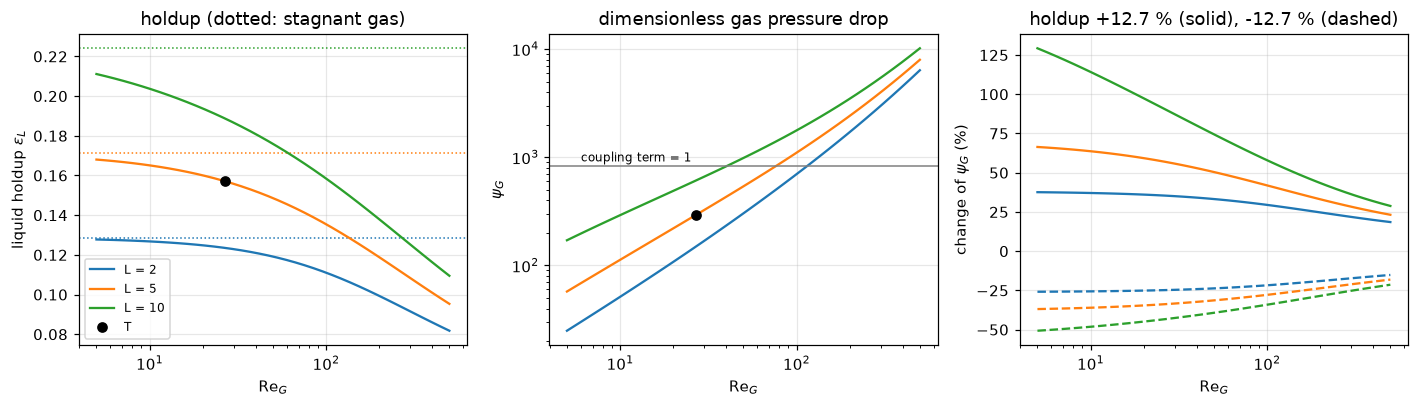

In [8]:
LIM = block_limits(P0, OPT)
GC = block_coupling(P0, OPT)
display(Markdown(
    f"At T: holdup $\\varepsilon_L$ = {R1['T_eps_L']:.4f} against {R1['T_eps_L'] / R1['T_holdup_over_stagnant']:.4f}"
    f" with stagnant gas (ratio {R1['T_holdup_over_stagnant']:.4f}); $\\psi_G$ = {R1['T_psi_G']:.1f};"
    f" $-dP/dz$ = {R1['T_minus_dPdz_Pa_per_m']:.0f} Pa/m; coupling term {R1['T_coupling']:.3f}."
    f" The coupling term reaches 1 at $G$ = {GC['T_G_coupling_one']:.4f} kg/(m² s) (root, L = 5)."
    f" With stagnant gas the liquid fills the pores ($\\delta$ = 1) at Re$_L$ = {LIM['T_Re_L_trickle_end']:.1f},"
    f" L = {LIM['T_L_trickle_end']:.2f} kg/(m² s). Sensitivity: d ln $\\psi$/d ln $\\varepsilon_L$ ="
    f" {R1['T_dlnpsi_dlneps']:.3f}; a holdup 12.7 % high moves $\\psi_G$ by {100 * R1['T_psi_factor_plus_12p7']:+.1f} %,"
    f" 12.7 % low by {100 * R1['T_psi_factor_minus_12p7']:+.1f} %."))

st_s = M.state(OP_S, P0, d_s, psi_s)
g_s = M.groups(OP_S, P0)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for i, Lv in enumerate(LS):
    sl = slice(i * RE_G.size, (i + 1) * RE_G.size)
    eps_stag = M.holdup(M.stagnant_delta(g_s["X_L"][sl][0], P0), T["eps"], g_s["eps0"])
    l, = ax[0].semilogx(RE_G, st_s["eps_L"][sl], label=f"L = {Lv:g}")
    ax[0].axhline(eps_stag, color=l.get_color(), ls=":", lw=1)
    ax[1].loglog(RE_G, st_s["psi"][sl], color=l.get_color())
    ax[2].semilogx(RE_G, 100 * M.psi_factor(st_s["eps_L"][sl], T["eps"], 1.127, P0), color=l.get_color())
    ax[2].semilogx(RE_G, 100 * M.psi_factor(st_s["eps_L"][sl], T["eps"], 0.873, P0), color=l.get_color(), ls="--")
ax[0].plot(g_T["Re_G"], R1["T_eps_L"], "ko", label="T")
ax[1].plot(g_T["Re_G"], R1["T_psi_G"], "ko")
ax[1].axhline(T["rho_L"] / T["rho_G"], color="grey", lw=1)
ax[1].text(6, T["rho_L"] / T["rho_G"] * 1.1, "coupling term = 1", fontsize=8)
ax[0].set(xlabel="Re$_G$", ylabel="liquid holdup $\\varepsilon_L$", title="holdup (dotted: stagnant gas)")
ax[1].set(xlabel="Re$_G$", ylabel="$\\psi_G$", title="dimensionless gas pressure drop")
ax[2].set(xlabel="Re$_G$", ylabel="change of $\\psi_G$ (%)", title="holdup +12.7 % (solid), -12.7 % (dashed)")
ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

### R3. Table 5, the surfactant ratios, recomputed

Jesser and Elgin lowered the surface tension of water with a surfactant; "The
surfactant did not alter the values of viscosity and density" (p. 57). At equal
Reynolds and Galileo numbers Eq. 34 gives the same $\delta$, so by Eq. 24 the dynamic
holdups differ only through the static holdup of Eq. 8:
$\varepsilon^D_i/\varepsilon^D_o = (\varepsilon - \varepsilon^0_i)/(\varepsilon - \varepsilon^0_o)$.
Because $\varepsilon^0 \le 1/20$ for every Eötvös number, this ratio is bounded for
any packed bed. The paper prints Calc. 1.81 and 2.12 at every liquid flux and says
"From these results we can see that the ratio of dynamic holdups tends to be
overestimated by our correlation." (p. 58).

100 L (printed)  Exp. 1 Calc. 1 (printed)  Exp. 2 Calc. 2 (printed)
          542.5    1.26              1.81    1.48              2.12
        1,356.3    1.24              1.81    1.32              2.12
        2,712.5    1.13              1.81    1.17              2.12
        4,068.8    1.07              1.81    1.10              2.12


- **Bound.** Maximised over $\mathrm{Eo}^{\ast}_o$ (root of the analytic slope) at the densest packing $\varepsilon$ = 0.2595, the model's ratio is at most 1.0361 (solution 1, at Eo* = 14.29) and 1.0510 (solution 2, at Eo* = 12.43); at $\varepsilon$ = 0.36, 1.0251 and 1.0354. Reaching Calc. 1.81 needs $\varepsilon$ below 0.1117, which no packed bed has.
- **Measured against the bound.** 8 of 8 measured ratios lie above the largest ratio the model can give; the smallest margins are 1.0328 and 1.0466 times the bound (counted in half-units of the printed last digit in The finding). Corrected, the model **under**-predicts every measured ratio.
- **Where the printed Eq. 35 gives Calc.** The printed form returns both 1.81 and 2.12 at 1 point in $\varepsilon$ = 0.27 to 0.95: $\varepsilon$ = 0.7051, Eo*$_o$ = 19.006 (water 72.8 mN/m; with 72.0 mN/m: 0.7413, 20.725). There the correct ratios are 1.0121 and 1.0168. The paper prints neither porosity nor diameter for the carbon rings, so this is consistent evidence that Calc. used the printed form, not proof. Over the rounding of the two printed Calc. values (each half a unit of its last digit), with one root at each corner of that box, the porosity ranges from 0.633 to 0.784.

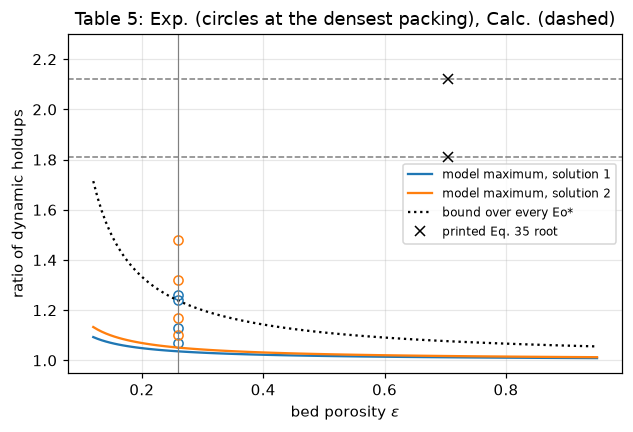

In [9]:
T5 = table5(P0, OPT)
s1, s2 = T5["_s"]
tab5 = pd.DataFrame({
    "100 L (printed)": [PRN[f"t5_L100_{i}"] for i in range(1, 5)],
    "Exp. 1": T5["_exp1"], "Calc. 1 (printed)": PRN["t5_calc1"],
    "Exp. 2": T5["_exp2"], "Calc. 2 (printed)": PRN["t5_calc2"]})
print(tab5.to_string(index=False))
n_above = int(np.sum(T5["_bound_values"] > 1))
display(Markdown(
    f"- **Bound.** Maximised over $\\mathrm{{Eo}}^{{\\ast}}_o$ (root of the analytic slope) at the densest packing"
    f" $\\varepsilon$ = {EPS_DENSE:.4f}, the model's ratio is at most {T5['t5_corrected_max_sol1_dense']:.4f}"
    f" (solution 1, at Eo* = {T5['t5_corrected_max_Eo_sol1_dense']:.2f}) and {T5['t5_corrected_max_sol2_dense']:.4f}"
    f" (solution 2, at Eo* = {T5['t5_corrected_max_Eo_sol2_dense']:.2f}); at $\\varepsilon$ = 0.36,"
    f" {T5['t5_corrected_max_sol1_eps036']:.4f} and {T5['t5_corrected_max_sol2_eps036']:.4f}."
    f" Reaching Calc. 1.81 needs $\\varepsilon$ below {T5['t5_eps_needed_for_calc1_upper']:.4f}, which no packed bed has.\n"
    f"- **Measured against the bound.** {n_above} of {T5['_bound_values'].size} measured ratios lie above the"
    f" largest ratio the model can give; the smallest margins are {T5['t5_exp_min_over_bound_sol1']:.4f}"
    f" and {T5['t5_exp_min_over_bound_sol2']:.4f} times the bound (counted in half-units of the printed last digit in The finding)."
    f" Corrected, the model **under**-predicts every measured ratio.\n"
    f"- **Where the printed Eq. 35 gives Calc.** The printed form returns both 1.81 and 2.12 at"
    f" {T5['t5_printed_n_roots']} point in $\\varepsilon$ = 0.27 to 0.95: $\\varepsilon$ = {T5['t5_printed_eps']:.4f},"
    f" Eo*$_o$ = {T5['t5_printed_Eo_o']:.3f} (water 72.8 mN/m; with 72.0 mN/m: {T5['t5_printed_eps_sigma72']:.4f},"
    f" {T5['t5_printed_Eo_o_sigma72']:.3f}). There the correct ratios are {T5['t5_corrected_at_printed_sol1']:.4f}"
    f" and {T5['t5_corrected_at_printed_sol2']:.4f}. The paper prints neither porosity nor diameter for the"
    f" carbon rings, so this is consistent evidence that Calc. used the printed form, not proof. Over the rounding"
    f" of the two printed Calc. values (each half a unit of its last digit), with one root at each corner of that box,"
    f" the porosity ranges from {T5['t5_printed_eps_lo']:.3f} to {T5['t5_printed_eps_hi']:.3f}."))

eg = np.linspace(0.12, 0.95, 120)
fig, ax = plt.subplots(figsize=(6.5, 4))
for s, lab, ex in ((s1, "solution 1", T5["_exp1"]), (s2, "solution 2", T5["_exp2"])):
    l, = ax.plot(eg, [M.ratio_max(e, s, P0)[0] for e in eg], label=f"model maximum, {lab}")
    ax.plot(np.full(4, EPS_DENSE), ex, "o", color=l.get_color(), mfc="none")
ax.plot(eg, M.ratio_sup(eg, P0), "k:", label="bound over every Eo*")
for cval in (num(PRN["t5_calc1"]), num(PRN["t5_calc2"])):
    ax.axhline(cval, color="grey", ls="--", lw=1)
ax.plot([T5["t5_printed_eps"]] * 2, [num(PRN["t5_calc1"]), num(PRN["t5_calc2"])], "kx", label="printed Eq. 35 root")
ax.axvline(EPS_DENSE, color="grey", lw=0.8)
ax.set(xlabel="bed porosity $\\varepsilon$", ylabel="ratio of dynamic holdups", ylim=(0.95, 2.3),
       title="Table 5: Exp. (circles at the densest packing), Calc. (dashed)")
ax.legend(fontsize=8)
plt.show()

### R4. The printed statistics as arithmetic

Several printed means are recombinations of other printed means. Each is recomputed
from the printed subset means weighted by their counts and set against its rounding
allowance: the shift the rounding of the inputs can cause plus half a unit of the
printed total.

In [10]:
ST = stats(P0, OPT)
assert ST["_n70_plus_28"] == int(num(PRN["p57_all_n"])), "70 + 28 points make the printed 98"
display(Markdown(
    f"| printed total | recombined from | value | gap over allowance |\n|---|---|---|---|\n"
    f"| Table 7 holdup, 12.7 % | 17 x 14.2, 42 x 12.2 | {ST['t7_eps_all_recombined_pct']:.4f} | {ST['t7_eps_gap_over_allowance']:.3f} |\n"
    f"| Table 7 pressure drop, 21.9 % | 17 x 25.7, 32 x 19.9 | {ST['t7_psi_all_recombined_pct']:.4f} | {ST['t7_psi_gap_over_allowance']:.3f} |\n"
    f"| Table 4 this work, 14.9 % | 57 x 11.9, 13 x 28.3 (p. 57) | {ST['t4_this_work_recombined_pct']:.4f} | {ST['t4_gap_over_allowance']:.3f} |\n"
    f"| all 98 points, 15.2 % | 70 x 14.9, 28 x 16 (p. 57) | {ST['stag98_recombined_pct']:.4f} | {ST['stag98_gap_over_allowance']:.4f} |\n\n"
    f"{int(np.sum(np.array(ST['_gaps']) < 1))} of 4 recombinations fall inside their allowance: the statistics"
    f" are consistent with rounding. Table 3's two rows differ by {ST['t3_two_param_gain_pct']:.1f} points, the"
    f" \"only 3.4%\" of p. 56. Table 7 also shows that the 17 points with $d_c/d_p > 20$ that fixed the"
    f" exponent 4.8 sit inside both the 49 and the 59, so the stated deviations are not out-of-sample: their"
    f" pressure-drop deviation, 25.7 %, is the largest row of Table 7 (19.9 % on the other 32)."))

| printed total | recombined from | value | gap over allowance |
|---|---|---|---|
| Table 7 holdup, 12.7 % | 17 x 14.2, 42 x 12.2 | 12.7763 | 0.763 |
| Table 7 pressure drop, 21.9 % | 17 x 25.7, 32 x 19.9 | 21.9122 | 0.122 |
| Table 4 this work, 14.9 % | 57 x 11.9, 13 x 28.3 (p. 57) | 14.9457 | 0.457 |
| all 98 points, 15.2 % | 70 x 14.9, 28 x 16 (p. 57) | 15.2143 | 0.0625 |

4 of 4 recombinations fall inside their allowance: the statistics are consistent with rounding. Table 3's two rows differ by 3.4 points, the "only 3.4%" of p. 56. Table 7 also shows that the 17 points with $d_c/d_p > 20$ that fixed the exponent 4.8 sit inside both the 49 and the 59, so the stated deviations are not out-of-sample: their pressure-drop deviation, 25.7 %, is the largest row of Table 7 (19.9 % on the other 32).

### R5. Figure 8 against the band the text states

The paper says: "Note that the majority of the pressure drop data lies in the ±30%
region (Figure 7), whereas the liquid holdup data lie between the −20% and the +20%
lines (Figure 8)." (p. 59). Each readable marker of Figure 8 gives its own deviation
$\varepsilon_{cal}/\varepsilon_{exp} - 1$ from its coordinates, and its position
against the dashed lines as drawn. The readable markers are fewer than the 40
the plan requires for a mean, so the page counts markers outside the band and does not
compute a mean deviation. The blobs of touching markers are not counted; at least one
marker hidden in them sits on the lower line within its reading error.

                  symbol     exp     cal  deviation (%)  beyond the band (reading errors)
filled inverted triangle 0.05425 0.06400           16.1                              -2.4
             open circle 0.06528 0.06573           -0.9                             -11.5
             open circle 0.06798 0.06821           -1.3                             -11.7
  open inverted triangle 0.08281 0.12287           46.0                              10.8
             open square 0.11114 0.14782           30.9                               4.5
filled inverted triangle 0.11321 0.17747           54.3                              14.0
           open triangle 0.14159 0.10918          -24.1                               2.9
filled inverted triangle 0.16254 0.21884           32.5                               5.2
  open inverted triangle 0.19357 0.28350           44.1                              10.1
             open circle 0.21878 0.17436          -21.6                               1.0
  open inv

Of the 13 readable markers (the paper states 59 points; the others are in blobs), 7 lie above the +20 % line and 1 below the −20 % line, each by more than the reading error (2 px per coordinate), so 8 lie outside the band; 1 more sits within one reading error of a line (it lies 0.98 reading errors beyond its line). The blobs of touching markers are not counted; at least one marker hidden in them sits on the lower line within its reading error. Readable deviations range from -24.1 % to +54.3 %. The statement that the holdup data "lie between" the lines does not hold for the figure as printed. The drawn lines themselves: the solid diagonal sits 2.6 px above y = x from the ticks; the upper dashed line is +1.3 px from cal/exp = 1.2, the lower -0.5 px from 0.8 (and -7.1 px from 1/1.2), so the band is drawn as 0.8 to 1.2; these offsets are means over each line, which the upper dashed line departs from by drifting along its length.

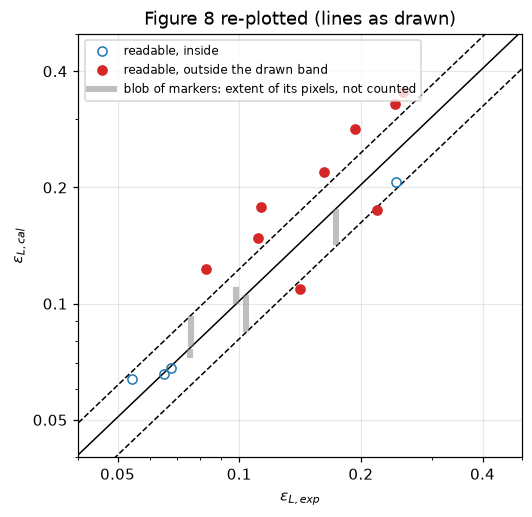

In [11]:
def block_fig8(P, o):
    """R5 and V4: Figure 8's readable markers against its drawn lines."""
    shift = {k: o["line_shift_px"].get(k, 0.0) / PXY for k in ("solid", "plus", "minus")}
    solid = LN["solid"] - shift["solid"]
    plus, minus = LN["plus"] - shift["plus"], LN["minus"] - shift["minus"]
    if o["band_pct"] is not None:
        b = o["band_pct"] / 100.0
        plus, minus = solid + np.log10(1 + b), solid + np.log10(1 - b)
    mk = MK if o["pair_split"] else MK[~MK.flag.str.contains("split by hand")]
    D = np.log10(mk.cal.values) - np.log10(mk.exp.values) - o["centre_shift_px"] / PXY
    dev = 10**(D - solid) - 1
    beyond = np.maximum(D - plus, minus - D)     # signed distance beyond the nearer drawn line, decades
    return {"fig8_n_readable": len(mk),
            "fig8_n_above_plus": int(np.sum(D - plus > E_D)), "fig8_n_below_minus": int(np.sum(minus - D > E_D)),
            "fig8_n_outside": int(np.sum(beyond > E_D)), "fig8_n_near": int(np.sum(np.abs(beyond) <= E_D)),
            "fig8_dev_max_pct": 100 * dev.max(), "fig8_dev_min_pct": 100 * dev.min(),
            "fig8_plus_line_vs_log12_px": (plus - solid - np.log10(1.2)) * PXY,
            "fig8_minus_line_vs_log08_px": (minus - solid - np.log10(0.8)) * PXY,
            "fig8_minus_line_vs_inv12_px": (minus - solid + np.log10(1.2)) * PXY,
            "fig8_diagonal_offset_px": solid * PXY,
            "_D": D, "_plus": plus, "_minus": minus, "_solid": solid, "_beyond": beyond, "_dev": dev}


F8 = block_fig8(P0, OPT)
dist = F8["_beyond"] / E_D                      # reading errors beyond the nearer drawn line
tab8 = MK[["symbol", "exp", "cal"]].assign(**{"deviation (%)": np.round(100 * F8["_dev"], 1),
                                              "beyond the band (reading errors)": np.round(dist, 1)})
print(tab8.to_string(index=False))
display(Markdown(
    f"Of the {F8['fig8_n_readable']} readable markers (the paper states {PRN['t7_n_eps_all']} points; the others are in"
    f" blobs), {F8['fig8_n_above_plus']} lie above the +20 % line and {F8['fig8_n_below_minus']} below the −20 %"
    f" line, each by more than the reading error ({READ_PX:g} px per coordinate), so {F8['fig8_n_outside']} lie"
    f" outside the band; {F8['fig8_n_near']} more sits within one reading error of a line (it lies"
    f" {', '.join(f'{d:.2f}' for d in dist[np.abs(dist) <= 1])} reading errors beyond its line)."
    f" The blobs of touching markers are not counted; at least one marker hidden in them sits on the lower line"
    f" within its reading error. Readable deviations range from {F8['fig8_dev_min_pct']:+.1f} %"
    f" to {F8['fig8_dev_max_pct']:+.1f} %. The statement that the holdup data \"lie between\" the lines does not hold"
    f" for the figure as printed. The drawn lines themselves: the solid diagonal sits {F8['fig8_diagonal_offset_px']:.1f} px"
    f" above y = x from the ticks; the upper dashed line is {F8['fig8_plus_line_vs_log12_px']:+.1f} px from"
    f" cal/exp = 1.2, the lower {F8['fig8_minus_line_vs_log08_px']:+.1f} px from 0.8 (and"
    f" {F8['fig8_minus_line_vs_inv12_px']:+.1f} px from 1/1.2), so the band is drawn as 0.8 to 1.2; these offsets are"
    f" means over each line, which the upper dashed line departs from by drifting along its length."))

fig, ax = plt.subplots(figsize=(5.2, 5))
xx = np.array([0.04, 0.5])
for k, ls in (("_solid", "-"), ("_plus", "--"), ("_minus", "--")):
    ax.loglog(xx, xx * 10**F8[k], "k", ls=ls, lw=1)
out = (F8["_D"] > F8["_plus"]) | (F8["_D"] < F8["_minus"])
ax.loglog(MK.exp[~out], MK.cal[~out], "o", mfc="none", color="C0", label="readable, inside")
ax.loglog(MK.exp[out], MK.cal[out], "o", color="C3", label="readable, outside the drawn band")
for r in CL.itertuples():
    xe = 10**((r.x_px - MK.x_px[0]) / PXX + np.log10(MK.exp[0]))   # the abscissa calibration
    ax.plot([xe, xe], [xe * 10**r.offset_min_dec, xe * 10**r.offset_max_dec], color="grey", lw=4, alpha=0.5)
ax.plot([], [], color="grey", lw=4, alpha=0.5, label="blob of markers: extent of its pixels, not counted")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_minor_formatter(plt.NullFormatter())
    axis.set_major_formatter(plt.FormatStrFormatter("%g"))
ax.set_xticks([0.05, 0.1, 0.2, 0.4])
ax.set_yticks([0.05, 0.1, 0.2, 0.4])
ax.set(xlabel="$\\varepsilon_{L,exp}$", ylabel="$\\varepsilon_{L,cal}$", xlim=(0.04, 0.5), ylim=(0.04, 0.5),
       title="Figure 8 re-plotted (lines as drawn)")
ax.legend(fontsize=8, loc="upper left")
plt.show()

### The finding

Each number below is set against its own uncertainty: a rounding allowance for a
printed value, the reading error for a digitised marker.

In [12]:
display(Markdown(
    f"1. **Derivation.** The chain from the balances to Eqs. 34, 50 and 51 re-derives. Its three"
    f" approximations at T: gas weight {R1['T_eps_L_shift_eq51_vs_eq21']:.2e} in holdup; 0.41 for 1/2.43"
    f" {100 * R1['T_delta_shift_041_vs_inv_a']:+.2f} % in the stagnant-gas $\\delta$ (0.41 is"
    f" {CV['exp34_halfunits_from_0p41']:.2f} half-units of its last digit from 1/2.43, a fair rounding);"
    f" Ergun 150, 1.75 instead of 180, 1.8 {100 * (R1['T_psi_G_ergun150'] / R1['T_psi_G'] - 1):+.1f} % in"
    f" $\\psi_G$.\n"
    f"2. **Table 5.** The paper says the ratio \"tends to be overestimated by our correlation\" (p. 58). That is"
    f" true of the printed Calc. ({T5['t5_n_calc_above_exp']} of 8 above Exp.), but Calc. does not follow from"
    f" Eqs. 8, 24 and 34: with Eq. 35 corrected, the largest ratio the model can give at any packed-bed porosity is"
    f" {T5['t5_corrected_max_sol1_dense']:.4f} and {T5['t5_corrected_max_sol2_dense']:.4f}, and"
    f" {int(np.sum(T5['_bound_values'] > 1))} of 8 measured ratios lie above it, the closest by"
    f" {T5['t5_margin_halfunits_sol1']:.1f} and {T5['t5_margin_halfunits_sol2']:.1f} half-units of their"
    f" printed last digit. The corrected model under-predicts all eight. The printed Eq. 35 reproduces both"
    f" Calc. values at one bed ({T5['t5_printed_n_roots']} root in porosity 0.27 to 0.95), $\\varepsilon$ = {T5['t5_printed_eps']:.3f},"
    f" Eo*$_o$ = {T5['t5_printed_Eo_o']:.2f}; the paper prints no porosity for that bed, and over the rounding of the two"
    f" printed Calc. values the porosity ranges from {T5['t5_printed_eps_lo']:.2f} to {T5['t5_printed_eps_hi']:.2f}.\n"
    f"3. **Statistics.** {int(np.sum(np.array(ST['_gaps']) < 1))} of 4 recombined means fall inside their rounding"
    f" allowance (largest {max(ST['_gaps']):.3f} of it): consistent with rounding.\n"
    f"4. **Figure 8.** The paper says the holdup data \"lie between the −20% and the +20% lines\" (p. 59)."
    f" Of the {len(MK)} readable markers, {F8['fig8_n_outside']} lie outside the lines as drawn"
    f" ({F8['fig8_n_above_plus']} above, {F8['fig8_n_below_minus']} below) by more than the reading error, the closest"
    f" {np.min(dist[dist > 1]):.1f} reading errors beyond its line, and {F8['fig8_n_near']} more sits within one reading"
    f" error of a line. The rest of the {PRN['t7_n_eps_all']} points the paper states sit in blobs of touching markers, which are"
    f" not counted; at least one marker hidden in them sits on the lower line within its reading error. So at least"
    f" {F8['fig8_n_outside']} of the {PRN['t7_n_eps_all']} points the paper states lie outside the drawn band. No mean deviation is"
    f" computed from {len(MK)} readable markers, so the stated 12.7 % is neither confirmed nor contradicted."))

1. **Derivation.** The chain from the balances to Eqs. 34, 50 and 51 re-derives. Its three approximations at T: gas weight -2.02e-04 in holdup; 0.41 for 1/2.43 +0.37 % in the stagnant-gas $\delta$ (0.41 is 0.30 half-units of its last digit from 1/2.43, a fair rounding); Ergun 150, 1.75 instead of 180, 1.8 -21.0 % in $\psi_G$.
2. **Table 5.** The paper says the ratio "tends to be overestimated by our correlation" (p. 58). That is true of the printed Calc. (8 of 8 above Exp.), but Calc. does not follow from Eqs. 8, 24 and 34: with Eq. 35 corrected, the largest ratio the model can give at any packed-bed porosity is 1.0361 and 1.0510, and 8 of 8 measured ratios lie above it, the closest by 6.8 and 9.8 half-units of their printed last digit. The corrected model under-predicts all eight. The printed Eq. 35 reproduces both Calc. values at one bed (1 root in porosity 0.27 to 0.95), $\varepsilon$ = 0.705, Eo*$_o$ = 19.01; the paper prints no porosity for that bed, and over the rounding of the two printed Calc. values the porosity ranges from 0.63 to 0.78.
3. **Statistics.** 4 of 4 recombined means fall inside their rounding allowance (largest 0.763 of it): consistent with rounding.
4. **Figure 8.** The paper says the holdup data "lie between the −20% and the +20% lines" (p. 59). Of the 13 readable markers, 8 lie outside the lines as drawn (7 above, 1 below) by more than the reading error, the closest 2.9 reading errors beyond its line, and 1 more sits within one reading error of a line. The rest of the 59 points the paper states sit in blobs of touching markers, which are not counted; at least one marker hidden in them sits on the lower line within its reading error. So at least 8 of the 59 points the paper states lie outside the drawn band. No mean deviation is computed from 13 readable markers, so the stated 12.7 % is neither confirmed nor contradicted.

## Validation

- **V1, limits of the solver.** With $k = 1$ the drag terms equal the dimensional
  Ergun gradients; at $G = 0$ the pair returns the stagnant-gas closed form
  $\delta = X_L^{1/2.43}$; the trickle end is the root of $X_L = 1$; as $L \to 0$,
  $\psi_G \to X_G(1 - \varepsilon^0/\varepsilon)^{-4.8}$, approached as $L^{1/2.43}$.
- **V2, two routes.** `newton` on all pairs against `brentq` on the eliminated
  equation over the whole sweep; `check_jacobian` on the analytic block Jacobian away
  from the solution; `residual_check` backward error at the solution.
- **V3, Table 5 routes.** The re-derived $\zeta$ form against the direct ratio over a
  grid of porosity and Eötvös number; the maximum by the analytic-slope root against a
  bounded maximisation refined from a scan of the whole window.
- **V4, raster reading.** The tick fit (its residuals are in the sidecar), the drawn
  lines against the forms they stand for (R5), the reading error per marker.
- **V5.** The 66 check values (above).

In [13]:
RT = block_routes(P0, OPT)
display(Markdown(
    f"- Ergun identity: {LIM['ergun_identity_gap']:.1e}, below 1e-13. Stagnant limit of the pair against the"
    f" closed form: {LIM['stagnant_limit_gap']:.1e}, below 1e-12. Trickle end, closed form against the root:"
    f" {LIM['trickle_end_closed_vs_root']:.1e}, below 1e-12. L to 0: $\\psi_G$ tends to"
    f" {LIM['T_psi_L0_over_dry']:.4f} times its dry-bed value; the approach exponent measured between L = 1e-10"
    f" and 1e-12 is {LIM['L0_approach_exponent']:.5f} against 1/2.43 = {1 / 2.43:.5f}.\n"
    f"- newton against brentq over {d_s.size} sweep points: largest relative gap {RT['sweep_newton_vs_brentq']:.1e},"
    f" below 1e-10; Jacobian against central differences {RT['jacobian_check_rel_error']:.1e}, below 1e-6;"
    f" backward error {RT['sweep_backward_error']:.1e}, below 1e-12.\n"
    f"- Table 5: re-derived form against the direct ratio {T5['t5_rederived_vs_direct_max']:.1e}, below 1e-13;"
    f" maximum by root against bounded search {T5['t5_max_root_vs_bounded_search']:.1e}, below 1e-10."))

- Ergun identity: 1.1e-16, below 1e-13. Stagnant limit of the pair against the closed form: 0.0e+00, below 1e-12. Trickle end, closed form against the root: 0.0e+00, below 1e-12. L to 0: $\psi_G$ tends to 1.9399 times its dry-bed value; the approach exponent measured between L = 1e-10 and 1e-12 is 0.41152 against 1/2.43 = 0.41152.
- newton against brentq over 120 sweep points: largest relative gap 1.4e-15, below 1e-10; Jacobian against central differences 1.9e-09, below 1e-6; backward error 6.0e-16, below 1e-12.
- Table 5: re-derived form against the direct ratio 4.4e-16, below 1e-13; maximum by root against bounded search 2.2e-16, below 1e-10.

### Claims and the break table

Every number above is registered once. Each break row injects one defect through a
parameter or a call argument, reruns the blocks it reaches, and hands every
recomputed number to `claims.breaks`; the last cell raises if a claim is caught by no
row.

In [14]:
VAL = dict(rtol=1e-6)
BLOCKS = {"T": block_T, "lim": block_limits, "coup": block_coupling, "routes": block_routes,
          "t5": table5, "stats": stats, "fig8": block_fig8}
BASE = {"T": R1, "lim": LIM, "coup": GC, "routes": RT, "t5": T5, "stats": ST, "fig8": F8}
for b, out in BASE.items():
    for name, x in out.items():
        if name.startswith("_") or name in claims.metrics:
            continue
        if name in ("T_eq13_residual_plus_density_ratio", "T_exact_balances_max", "stagnant_limit_gap",
                    "trickle_end_closed_vs_root"):
            claims.bound(name, x, max=1e-12, basis="tolerance", note="newton rtol 1e-12 / brentq xtol 1e-14")
        elif name in ("ergun_identity_gap", "t5_rederived_vs_direct_max"):
            claims.bound(name, x, max=1e-13, basis="identity", note="two forms of one expression")
        elif name == "sweep_newton_vs_brentq":
            claims.bound(name, x, max=1e-10, basis="tolerance", note="newton rtol 1e-12, brentq rtol 1e-15")
        elif name == "jacobian_check_rel_error":
            claims.bound(name, x, max=1e-6, basis="tolerance", note="central differences, step cbrt(eps)")
        elif name == "sweep_backward_error":
            claims.bound(name, x, max=1e-12, basis="tolerance", note="componentwise backward error")
        elif name == "t5_max_root_vs_bounded_search":
            claims.bound(name, x, max=1e-10, basis="tolerance", note="bounded search xatol 1e-12 in log10 Eo*")
        elif name == "fig8_n_readable":
            claims.exact(name, x, note="rows of the digitised CSV that are single markers")
        elif name in ("fig8_n_above_plus", "fig8_n_below_minus", "fig8_n_outside", "fig8_n_near"):
            edge = {"fig8_n_above_plus": [1.0], "fig8_n_below_minus": [1.0], "fig8_n_outside": [1.0],
                    "fig8_n_near": [-1.0, 1.0]}[name]
            side = F8["_D"] - F8["_plus"] if name == "fig8_n_above_plus" else (
                F8["_minus"] - F8["_D"] if name == "fig8_n_below_minus" else F8["_beyond"])
            m = float(min(np.min(np.abs(side / E_D - e)) for e in edge)) * E_D
            claims.exact(name, x, margin=m, min_margin=0.01 * E_D,
                         note="thresholded at one reading error beyond the drawn line; margin in decades, the"
                              " smallest distance of any marker to that threshold (the circle crossed by the"
                              " lower line sits just inside it, so it is counted with the near markers)")
        elif name == "t5_n_calc_above_exp":
            claims.exact(name, x, margin=float(np.min(np.abs(np.r_[num(PRN["t5_calc1"]) - T5["_exp1"],
                                                                num(PRN["t5_calc2"]) - T5["_exp2"]]))),
                         min_margin=0.01, note="printed Calc. against printed Exp.")
        elif name == "t5_printed_box_one_root":
            claims.exact(name, x, note="corners of the rounding box of the printed Calc. values with one root, of 4")
        elif name == "t5_printed_n_roots":
            claims.exact(name, x, note="find_roots over eps 0.27 to 0.95, poles excluded")
        elif name == "L0_approach_exponent":
            claims.value(name, x, rtol=1e-4)
        elif name.startswith("fig8_"):
            claims.value(name, x, rtol=1e-3)
        else:
            claims.value(name, x, **VAL)
claims.count("t5_n_exp_above_bound", T5["_bound_values"], 1.0, min_margin=0.01,
             note="Exp./bound against 1; densest packing")
claims.count("stats_n_within_allowance", ST["_gaps"], 1.0, above=False, min_margin=0.05)
claims.says("13", "fig8_n_readable")   # The data and R5 state the count of readable markers
print(f"{len(claims.metrics)} claims registered")

81 claims registered


In [15]:
ROWS = [
    ("k_G exponent 4.0 for 4.8", dict(c=4.0), ("T", "lim", "coup")),
    ("k_L exponent 2.2 for 2.43", dict(a=2.2), ("T", "lim", "stats")),
    ("Re* without the viscosity, as the nomenclature prints it", dict(re_mu=False), ("T", "lim")),
    ("gas weight kept (Eq. 21) where Eq. 51 drops it", dict(exact=True), ("T", "lim")),
    ("Ergun A 150 in the dimensional route only", dict(dim_A=150.0), ("lim",)),
    ("inertial Ergun constant B = 0", dict(B=0.0), ("T", "lim")),
    ("static holdup zero (Eq. 8 constant 1e30)", dict(eo_a=1e30), ("T", "lim")),
    ("gas density doubled in the coupling root", dict(rho_G_factor=2.0), ("coup",)),
    ("Eq. 34 exponent taken as 1/2.43 exactly", dict(e34=1 / 2.43), ("T",)),
    ("stagnant-limit closed form with the printed 0.41", dict(limit_exp=0.41), ("lim",)),
    ("trickle-end closed form with A = 150", dict(flood_A_closed=150.0), ("lim",)),
    ("exact-variant balance check run on Eq. 51", dict(balance_exact=False), ("T",)),
    ("newton given a = 2.42 while brentq keeps 2.43", dict(newton_a=2.42), ("routes",)),
    ("Jacobian without dr1/dpsi in the check", dict(drop_jac=True), ("routes",)),
    ("newton stopped after one iteration", dict(maxfev=1), ("routes",)),
    ("porosity floor 0.10 for the densest packing", dict(eps_floor=0.10), ("t5",)),
    ("printed Eq. 35 in the corrected-ratio function", dict(t5_form="printed"), ("t5",)),
    ("Eq. 36 constant 25 for 20", dict(eo_a=25.0), ("t5",)),
    ("Calc. 1.81 read as 1.18", dict(printed_override={"t5_calc1": "1.18"}), ("t5",)),
    ("Calc. 2.12 read as 2.21", dict(printed_override={"t5_calc2": "2.21"}), ("t5",)),
    ("bounded search window ending at Eo* = 5", dict(search_hi=5.0), ("t5",)),
    ("printed Calc. values taken to +-0.05 for +-0.005", dict(calc_half=0.05), ("t5",)),
    ("Table 7 subset counts swapped", dict(t7_swap=True), ("stats",)),
    ("13 other-fluid points read as 31", dict(printed_override={"p57_other_n": "31"}), ("stats",)),
    ("Jesser-Elgin 16 % read as 18 %", dict(printed_override={"p57_jesser_e_pct": "18"}), ("stats",)),
    ("Table 3 a != b deviation 11.4 read as 11.9", dict(printed_override={"t3_free_e_pct": "11.9"}), ("stats",)),
    ("Figure 8 hand-split pairs not counted", dict(pair_split=False), ("fig8",)),
    ("Figure 8 band read at +-30 %", dict(band_pct=30.0), ("fig8",)),
    ("Figure 8 band read at +-10 %", dict(band_pct=10.0), ("fig8",)),
    ("Figure 8 marker centres 2 px low", dict(centre_shift_px=2.0), ("fig8",)),
    ("Figure 8 upper dashed line read 3 px high", dict(line_shift_px={"plus": -3.0}), ("fig8",)),
    ("Figure 8 lower dashed line read 3 px low", dict(line_shift_px={"minus": 3.0}), ("fig8",)),
    ("Figure 8 solid diagonal read 3 px low", dict(line_shift_px={"solid": 3.0}), ("fig8",)),
]
claims.define_rows([r[0] for r in ROWS])
PKEYS = set(M.params())
EXTRA = {"t5": ("t5_n_exp_above_bound", lambda o: int(np.sum(o["_bound_values"] > 1))),
         "stats": ("stats_n_within_allowance", lambda o: int(np.sum(np.array(o["_gaps"]) < 1)))}
BREAK = []
for label, ch, blocks in ROWS:
    P_ = M.params(**{k: v for k, v in ch.items() if k in PKEYS})
    o_ = dict(OPT, **{k: v for k, v in ch.items() if k not in PKEYS})
    n, caught = 0, []
    for b in blocks:
        try:
            out = BLOCKS[b](P_, o_)
        except Exception as exc:          # a study that cannot run records nan for its claims
            print(f"  [{label}] block {b} raised: {exc}")
            out = {k: np.nan for k in BASE[b]}
        if b in EXTRA and "_bound_values" in out or b == "stats" and "_gaps" in out:
            name, fn = EXTRA[b]
            out[name] = fn(out)
        for name, v in out.items():
            if name in claims.metrics and not name.startswith("_"):
                n += 1
                if claims.breaks(label, name, v):
                    caught.append(name)
    BREAK.append((label, n, caught))
caught_by = {}
for label, n, cs in BREAK:
    for c in cs:
        caught_by.setdefault(c, []).append(label)
print(f"{len(BREAK)} rows; per row: claims recomputed, claims caught")
for label, n, cs in BREAK:
    print(f"  {n:3d} {len(cs):3d}  {label}")
miss = sorted(set(claims.metrics) - set(caught_by) - {"fig8_n_readable"})
print(f"{len(caught_by)} of {len(claims.metrics)} claims caught by at least one row; not caught: {miss or 'none'}")

33 rows; per row: claims recomputed, claims caught
   26  14  k_G exponent 4.0 for 4.8
   37  16  k_L exponent 2.2 for 2.43
   25  17  Re* without the viscosity, as the nomenclature prints it
   25  14  gas weight kept (Eq. 21) where Eq. 51 drops it
    7   1  Ergun A 150 in the dimensional route only
   25  16  inertial Ergun constant B = 0
   25  14  static holdup zero (Eq. 8 constant 1e30)
    1   1  gas density doubled in the coupling root
   18   2  Eq. 34 exponent taken as 1/2.43 exactly
    7   1  stagnant-limit closed form with the printed 0.41
    7   3  trickle-end closed form with A = 150
   18   1  exact-variant balance check run on Eq. 51
    3   1  newton given a = 2.42 while brentq keeps 2.43
    3   1  Jacobian without dr1/dpsi in the check
    3   2  newton stopped after one iteration
   29  10  porosity floor 0.10 for the densest packing
   29   4  printed Eq. 35 in the corrected-ratio function
   29  18  Eq. 36 constant 25 for 20
   29   4  Calc. 1.81 read as 1.18
  

## What pymrm adds

pymrm contributes the coupled solve and the checks, not the model. `pymrm.newton`
solves Eqs. 50 and 51 as the pair the paper writes, for all sweep points at once,
with the analytic block Jacobian, bounds that keep $\delta$ in (0, 1) and a relative
step test; `pymrm.checks.find_roots` locates the gas flux where the coupling term
reaches 1, the trickle end, the maximum of the Table 5 ratio and every root of the
printed Eq. 35, and refuses a scan that does not return exactly one;
`check_jacobian` and `residual_check` verify the Jacobian and the solution. Plainly:
the scalar elimination solved with `brentq` point by point (the page's second route)
gives every holdup and pressure drop on this page alone, and nothing here is
discretised, so there is no grid error and no observed order. The findings on the
paper (the bound on Table 5, the recombined statistics, the Figure 8 count) are
algebra and counting, not pymrm.

## Reuse

- **Another packing or fluid:** change `T` (diameter, porosity, properties). Measure
  single-phase pressure drop and fit `A`, `B` for the bed if possible; the paper
  reports that most single-phase data did not follow 180 and 1.8 (p. 58).
- **Another relative-permeability law:** replace `a` or `c` in `M.params`, or the
  power laws in `pair_residual`; the pair, its Jacobian and both routes stay.
- **Inside a reactor model:** call `M.solve_pair` for the holdup and pressure drop
  of every axial cell at once (the operating dictionary takes arrays).
- **Limits:** air-water, the Summary ranges of p. 60, low interaction; the surfactant
  effect is under-predicted by the corrected model (R3), so do not use it for
  surface-tension effects.
- Related pages: `G1.1` (Larkins tables), `G1.7` (coupled correlations at pressure),
  `G1.8` (wetting), `A1.1` (Ergun).

In [16]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for G1.3:
  T_X_L                              = 0.089043         value  rtol 1e-06
  T_X_G                              = 22.652           value  rtol 1e-06
  T_delta                            = 0.32645          value  rtol 1e-06
  T_eps_L                            = 0.15705          value  rtol 1e-06
  T_psi_G                            = 292.88           value  rtol 1e-06
  T_minus_dPdz_Pa_per_m              = 3436.1           value  rtol 1e-06
  T_coupling                         = 0.35217          value  rtol 1e-06
  T_eps_L_stagnant_eq34              = 0.17179          value  rtol 1e-06
  T_holdup_over_stagnant             = 0.91663          value  rtol 1e-06
  T_eps_L_shift_eq51_vs_eq21         = -0.00020155      value  rtol 1e-06
  T_delta_shift_041_vs_inv_a         = 0.0036895        value  rtol 1e-06
  T_eps_L_ergun150                   = 0.15294          value  rtol 1e-06
  T_psi_G_ergun150                   = 231.48           value  rtol 1e-06
  T_dlnpsi_dlneps    